# 02 - Inspeção de CT, Pré-processamento e Qualidade dos Recortes (*Crops*)

## 1. Enquadramento e Objetivos do Notebook

Este notebook inspeciona os volumes de Tomografia Computorizada (CT) utilizados na pipeline, os respetivos valores na escala Hounsfield (HU) e a geometria nativa das aquisições. Audita os espaçamentos de origem para fundamentar a grelha isotrópica configurada, gera recortes baseados nas uniões de contornos para os candidatos elegíveis de LIDC e LNDb de treino e apresenta métricas de qualidade e exclusões. Os recortes principais têm dimensões variáveis, determinadas pelos contornos e pelo contexto CT configurado; não correspondem aos cubos de tamanho fixo usados no Notebook 05.

> **Pré-requisito:** Antes de executar este notebook, é indispensável concluir a execução e a revisão manual supervisionada do **Notebook 01**.

### Princípios Técnicos e Decisões de Processamento

* **Limites HU dos recortes:** Com a configuração atual, os recortes de produção são reamostrados com interpolação linear para uma grelha de 0,4 mm, limitados ao intervalo [-1000, 400] HU e guardados em `float32`. Os limites são aplicados depois da interpolação. Como há reamostragem, os valores podem ser interpolados e não correspondem necessariamente aos valores de voxels individuais da aquisição. As regiões nativas preservam o espaçamento, a geometria e os voxels decodificados da fonte, sem reamostragem.
* **Recortes de contorno e contexto:** Os recortes principais seguem os contornos retidos e incluem o contexto CT configurado - 6 mm por face, por defeito. A máscara é reamostrada com interpolação pelo vizinho mais próximo e o contexto acrescentado à máscara é preenchido com zeros.
* **Consistência da pipeline:** A atualização dos recortes de contorno invalida as características radiómicas dependentes, que devem ser recalculadas. Os recortes e as exportações esféricos independentes do Notebook 05 são preservados.
* **Elegibilidade no LNDb:** São recortados apenas os achados de treino classificados como nódulos, com todas as avaliações de malignidade retidas válidas, na escala de 1 a 5, e que não foram removidos na revisão manual das classificações. Tal como no LIDC, os recortes só são gerados depois de concluída essa revisão, e os achados removidos (`excluded_by_review`) permanecem na tabela de auditoria sem recorte. Não-nódulos e avaliações inválidas ou desconhecidas também permanecem na tabela sem recorte.
* **Candidatos de teste:** Os candidatos não rotulados do conjunto de teste são processados no Notebook 05, que preserva a sua ordem original.

In [1]:
from pathlib import Path
import sys

PROJECT_ROOT = next(
    (
        p
        for p in (Path.cwd(), *Path.cwd().parents)
        if (p / "pyproject.toml").is_file() and (p / "data").is_dir()
    ),
    None,
)
if PROJECT_ROOT is None:
    raise RuntimeError("Start Jupyter from project/ or project/notebooks/")
sys.path.insert(0, str(PROJECT_ROOT / "src"))
from IPython.display import display


In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from lung_project.paths import LIDC_ROOT
from lung_project.prepared import read_prepared
from lung_project.ct import read_lidc_series, window_hu

# Example scan: the first patient (then series UID) in the prepared LIDC table whose DICOMs are available.
example_scans = (
    read_prepared("lidc")[["patient_id", "scan_uid"]].drop_duplicates().sort_values(["patient_id", "scan_uid"])
)
series_uid = next(uid for uid in example_scans["scan_uid"] if (LIDC_ROOT / "LIDC-IDRI" / uid).is_dir())
series_dir = LIDC_ROOT / "LIDC-IDRI" / series_uid
image = read_lidc_series(series_dir)
volume = window_hu(image)
print("Series UID:", series_uid)
print("Voxel array shape (z, y, x):", volume.shape)
print("Spacing (x, y, z) mm:", image.GetSpacing())


Series UID: 1.3.6.1.4.1.14519.5.2.1.6279.6001.179049373636438705059720603192
Voxel array shape (z, y, x): (133, 512, 512)
Spacing (x, y, z) mm: (0.703125, 0.703125, 2.5)


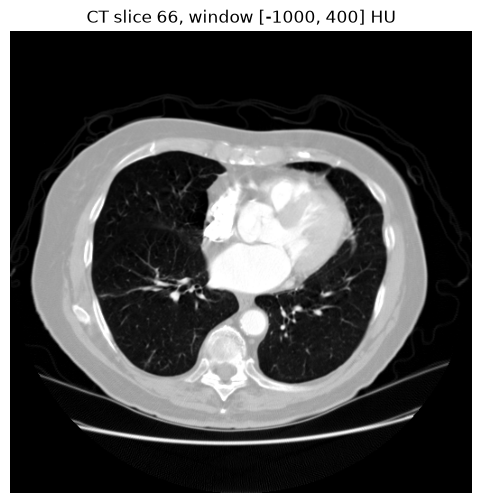

In [3]:
middle = volume.shape[0] // 2
fig, ax = plt.subplots(figsize=(6, 6))
ax.imshow(volume[middle], cmap="gray", vmin=-1000, vmax=400)
ax.set(title=f"CT slice {middle}, window [-1000, 400] HU")
ax.axis("off")
plt.show()


## Contrato de Pré-processamento (*Preprocessing Contract*)

A pipeline mantém nos manifestos os identificadores dos candidatos, as coordenadas físicas e a geometria dos volumes. Regista também os avisos de qualidade e os casos que ficam sem recorte. No LIDC, as séries são lidas pela ordenação indicada pelos metadados DICOM.

* **Origem das anotações:** No LIDC-IDRI, os contornos provêm dos ficheiros XML e são acedidos através das anotações verificadas pela biblioteca `pylidc`. No conjunto de treino do LNDb, as máscaras dos leitores são fornecidas em ficheiros MetaImage, lidos através dos respetivos ficheiros `.mhd`.
* **Recortes baseados em contornos:** Para gerar estes recortes, a pipeline combina as máscaras dos leitores retidos através da sua união espacial. No LIDC, as máscaras são reconstruídas a partir dos contornos, respeitando as regiões incluídas e excluídas por cada leitor; no LNDb, são selecionadas a partir das máscaras originais de cada leitor. Nódulos LNDb anotados apenas por um ponto centroidal permanecem registados, mas não produzem recortes de contorno nem entram na extração de características baseada em contornos.

In [4]:
import json
from hashlib import sha256
from lung_project.paths import LNDB_ROOT, OUTPUT_ROOT
from lung_project.ct import CropRules
from lung_project.scan_pipeline import attach_lidc_audit, process_lidc, process_lndb, rules_id
from lung_project.prepared import read_prepared, write_prepared, crop_payload
from lung_project.quality import lidc_geometry_inventory, lndb_spacing
from lung_project.paths import output_file
from lung_project.quality import crop_quality_summary
from lung_project.progress import notebook_progress


## 1. Inspeção do Espaçamento antes da Definição da Grelha de Saída

A auditoria ao LIDC regista a geometria DICOM de cada série, incluindo o espaçamento mínimo observado entre cortes, descontinuidades não uniformes e eventuais posições duplicadas. Para evitar a perda de resolução (*coarsening*), a verificação conservadora adota esse espaçamento mínimo como referência para o eixo Z no LIDC; no LNDb, utiliza-se o espaçamento Z definido nos cabeçalhos MetaImage.

A auditoria percorre as séries do LIDC selecionadas para geração de candidatos e os cabeçalhos MetaImage disponíveis para o conjunto de treino do LNDb. Esta verificação é executada antes do carregamento da configuração-alvo em `config/scan_processing.json`, sendo a geometria completa revalidada no momento de criação dos recortes.

Esta verificação determina se a grelha-alvo tem, em algum eixo, um espaçamento superior ao da aquisição original - o que reduziria a resolução espacial nesse eixo. Como a reamostragem não recupera a informação original nem garante a reprodução exata dos valores dos voxels, os exames originais são preservados e os recortes nativos mantêm os voxels da região adquirida.


In [5]:
lidc_candidates = read_prepared("lidc")
lidc_inventory = lidc_geometry_inventory(LIDC_ROOT, lidc_candidates.scan_uid.unique(), progress=notebook_progress())
lidc_spacing = lidc_inventory[
    [
        "series_instance_uid",
        "pixel_spacing_column_mm",
        "pixel_spacing_row_mm",
        "calculated_median_slice_gap_mm",
        "calculated_min_slice_gap_mm",
    ]
].copy()
lidc_spacing.columns = ["scan", "x", "y", "z", "min_z_gap"]
lidc_spacing.insert(0, "subset", "lidc")
spacing_audit = pd.concat([lidc_spacing, lndb_spacing(LNDB_ROOT / "data", "lndb_train")], ignore_index=True)
display(
    spacing_audit.groupby("subset")[["x", "y", "z", "min_z_gap"]].quantile([0, 0.05, 0.5, 0.95, 1]).round(3)
)


LIDC geometry headers: 883/883 series

x      y      z  min_z_gap
subset                                         
lidc       0.00  0.461  0.461  0.450      0.450
           0.05  0.562  0.562  0.625      0.625
           0.50  0.703  0.703  1.250      1.250
           0.95  0.830  0.830  3.000      3.000
           1.00  0.977  0.977  5.000      5.000
lndb_train 0.00  0.433  0.433  0.500      0.500
           0.05  0.493  0.493  1.000      1.000
           0.50  0.644  0.644  1.000      1.000
           0.95  0.771  0.771  1.000      1.000
           1.00  0.895  0.895  1.400      1.400

### Comparação de Grelhas Candidatas antes da Seleção

Para cada espaçamento isotrópico candidato, contamos quantos exames apresentam pelo menos um eixo com espaçamento de origem inferior ao espaçamento-alvo. Nesses casos, a grelha-alvo teria um espaçamento maior nesse eixo, reduzindo a resolução espacial. Para esta comparação, usamos o menor intervalo entre cortes observado no LIDC e o espaçamento Z indicado nos cabeçalhos MetaImage do LNDb.

Contamos também os exames em que o espaçamento mediano entre cortes é superior ao dobro do espaçamento-alvo. Esta medida ajuda a identificar grelhas muito finas em relação à aquisição original, que exigiriam maior interpolação no eixo Z.

Os custos de armazenamento estimados referem-se a um cubo comparativo em `float32`, com cerca de **64,8 mm entre os centros dos voxels externos**. Esta dimensão serve apenas para comparar as grelhas candidatas: os recortes de contorno de produção têm dimensões variáveis, definidas pela união das máscaras e pela margem de contexto configurada.

In [6]:
# Compare possible isotropic grids using every audited source spacing, before loading the chosen rule.
# Counts are scans, not annotation rows. Float32 preserves the interpolated HU range.
options = []
for target_mm in (1.0, 0.8, 0.6, 0.5, 0.4):
    side = 2 * round(32.4 / target_mm) + 1  # Centered samples over about 64.8 mm.
    for subset, group in spacing_audit.groupby("subset", sort=False):
        options.append(
            {
                "target_mm": target_mm,
                "subset": subset,
                "scans": len(group),
                "crop_side_voxels": side,
                "outer_center_span_mm": round((side - 1) * target_mm, 1),
                "MiB_per_float32_crop": round(side**3 * 4 / 2**20, 2),
                "any_axis_coarsened": int(
                    (group[["x", "y", "min_z_gap"]] < target_mm - 1e-6).any(axis=1).sum()
                ),
                "z_upsampled_over_2x": int((group.z / target_mm > 2).sum()),
            }
        )
spacing_options = pd.DataFrame(options)
display(spacing_options.set_index(["target_mm", "subset"]))
print("0.4 mm scan count with a finer source axis by dataset:")
display(
    spacing_options.loc[
        spacing_options.target_mm.eq(0.4), ["subset", "scans", "any_axis_coarsened", "z_upsampled_over_2x"]
    ].reset_index(drop=True)
)


scans  crop_side_voxels  outer_center_span_mm  \
target_mm subset                                                      
1.0       lidc          883                65                  64.0   
          lndb_train    236                65                  64.0   
0.8       lidc          883                81                  64.0   
          lndb_train    236                81                  64.0   
0.6       lidc          883               109                  64.8   
          lndb_train    236               109                  64.8   
0.5       lidc          883               131                  65.0   
          lndb_train    236               131                  65.0   
0.4       lidc          883               163                  64.8   
          lndb_train    236               163                  64.8   

                      MiB_per_float32_crop  any_axis_coarsened  \
target_mm subset                                                 
1.0       lidc                        1.05                 883   
          lndb_train                  1.05                 236   
0.8       lidc                        2.03                 801   
          lndb_train                  2.03                 231   
0.6       lidc                        4.94                 145   
          lndb_train                  4.94                  80   
0.5       lidc                        8.58                   4   
          lndb_train                  8.58                  15   
0.4       lidc                       16.52                   0   
          lndb_train                 16.52                   0   

                      z_upsampled_over_2x  
target_mm subset                           
1.0       lidc                        328  
          lndb_train                    0  
0.8       lidc                        419  
          lndb_train                    0  
0.6       lidc                        619  
          lndb_train                    1  
0.5       lidc                        619  
          lndb_train                   53  
0.4       lidc                        725  
          lndb_train                  234

0.4 mm scan count with a finer source axis by dataset:


,subset,scans,any_axis_coarsened,z_upsampled_over_2x
0,lidc,883,0,725
1,lndb_train,236,0,234


### Aplicação da Regra Selecionada

Com base na auditoria, seleciona-se uma grelha isotrópica de **0,4 mm nos três eixos (X, Y e Z)**. Entre as opções avaliadas, é a única que não define, em nenhum exame, um espaçamento-alvo superior ao espaçamento nativo: os menores espaçamentos observados são 0,433 mm (LNDb, X e Y) e 0,45 mm (LIDC, Z), ambos acima de 0,4 mm. Grelhas ainda mais finas também evitariam esta perda de resolução, mas aumentariam o armazenamento e a interpolação sem acrescentar informação da aquisição. A verificação no código confirma esta condição e interrompe a execução com uma exceção se algum exame apresentar um espaçamento nativo inferior ao alvo.


In [7]:
config_path = PROJECT_ROOT / "config" / "scan_processing.json"
settings = json.loads(config_path.read_text())
rules = CropRules.from_json(config_path)
save_native_crop = bool(settings["save_native_crop"])
impact = []
for subset, group in spacing_audit.groupby("subset"):
    row = {"subset": subset, "scans": len(group)}
    for axis, target in zip("xyz", rules.spacing_mm):
        row[f"{axis}_coarser_over_25pct"] = int((target / group[axis] > 1.25).sum())
        row[f"{axis}_upsampled_over_2x"] = int((group[axis] / target > 2).sum())
    impact.append(row)
display(pd.DataFrame(impact))
minimum_source_spacing = spacing_audit.groupby("subset")[["x", "y", "min_z_gap"]].min()
display(
    minimum_source_spacing.rename(
        columns={"x": "minimum_x_mm", "y": "minimum_y_mm", "min_z_gap": "minimum_z_gap_mm"}
    )
)
spacing_margin = minimum_source_spacing - np.asarray(rules.spacing_mm)
print("Minimum source spacing minus target, in mm:")
display(
    spacing_margin.rename(columns={"x": "margin_x_mm", "y": "margin_y_mm", "min_z_gap": "margin_z_gap_mm"})
)
assert (spacing_audit[["x", "y", "min_z_gap"]].to_numpy() + 1e-6 >= np.asarray(rules.spacing_mm)).all(), (
    "Target grid coarsens a source axis"
)
print("Rules ID:", rules_id(rules, "reader_union"), "spacing (x, y, z) mm:", rules.spacing_mm)
print("Notebook 05 sphere grid:", rules.size_voxels, "field of view mm:", rules.field_of_view_mm)
print("Main crop dimensions: expanded reader-union bounding boxes")
print("CT context margin per face (mm), mask unchanged:", rules.contour_margin_mm)
print("HU window:", rules.hu_window, "output dtype:", rules.output_dtype)
print("Interpolation:", rules.interpolation, "pad HU:", rules.pad_hu)
print("Save native voxel regions:", save_native_crop)


,subset,scans,x_coarser_over_25pct,x_upsampled_over_2x,y_coarser_over_25pct,y_upsampled_over_2x,z_coarser_over_25pct,z_upsampled_over_2x
0,lidc,883,0,85,0,85,0,725
1,lndb_train,236,0,5,0,5,0,234


,minimum_x_mm,minimum_y_mm,minimum_z_gap_mm
subset,,,
lidc,0.460938,0.460938,0.449951
lndb_train,0.432789,0.432789,0.500000


Minimum source spacing minus target, in mm:


,margin_x_mm,margin_y_mm,margin_z_gap_mm
subset,,,
lidc,0.060937,0.060937,0.049951
lndb_train,0.032789,0.032789,0.100000


Rules ID: 03914cf6bc66 spacing (x, y, z) mm: (0.4, 0.4, 0.4)
Notebook 05 sphere grid: (23, 23, 23) field of view mm: (9.200000000000001, 9.200000000000001, 9.200000000000001)
Main crop dimensions: expanded reader-union bounding boxes
CT context margin per face (mm), mask unchanged: 6.0
HU window: (-1000, 400) output dtype: float32
Interpolation: linear pad HU: -1000
Save native voxel regions: True


### Interpolação das Máscaras e Extração de Características

As máscaras são reamostradas pelo método do vizinho mais próximo (*nearest neighbor*), sem dilatação explícita. As estatísticas radiómicas são calculadas dentro da máscara reamostrada, enquanto os filtros de imagem podem utilizar o contexto CT incluído no recorte.

## 2. Interpretação das Fontes e Identificação dos Candidatos

* **LIDC-IDRI:** O ficheiro `outputs/prepared/lidc.csv` contém os nódulos com diâmetro igual ou superior a 3 mm, agrupados com `pylidc.Scan.cluster_annotations()` com base na geometria dos contornos. Grupos com mais de quatro anotações ou marcas distintas do mesmo leitor exigem revisão do agrupamento. A revisão de malignidade é necessária apenas quando a amplitude é >= 3 e a concordância exata entre leitores é < 2/3. Com concordância >= 2/3, a amplitude elevada não exige essa revisão. Casos pendentes de revisão no Notebook 01 não são recortados antes de essa revisão estar concluída. Para cada candidato, o centro é calculado a partir dos contornos: X e Y são expressos em píxeis e Z corresponde à posição no paciente. Estas coordenadas são convertidas para coordenadas físicas através da geometria DICOM. Os fatores DICOM de reescalonamento (*rescale slope* e *intercept*) são verificados; como o SimpleITK já os aplica durante a leitura, não se efetua uma segunda conversão.
* **LNDb de treino:** O ficheiro `trainNodules_gt.csv` reúne os nódulos dos radiologistas e fornece coordenadas X, Y e Z no espaço físico do paciente, conforme a documentação do LNDb. Os nódulos e não-nódulos são mantidos na tabela preparada com as respetivas etiquetas; a elegibilidade da classificação-alvo é determinada separadamente do estado do recorte.

**Verificação dos valores do LNDb**

Os valores dos volumes MetaImage do LNDb são utilizados tal como fornecidos, sem fatores de reescalonamento DICOM. Para cada exame, registam-se o intervalo de intensidades amostrado, as dimensões, o espaçamento e a orientação. Valores fora do esperado são assinalados para auditoria, sem aplicação de deslocamentos arbitrários.

In [8]:
# Select label-owned fields only. A crop rerun must not carry old features into its output.
from lung_project.prepared import stage_inputs

label_inputs = stage_inputs
lidc_candidates = label_inputs("lidc")
lndb_train = label_inputs("lndb_train")
from lung_project.dataset import lndb_crop_exclusions

exclusions = lndb_crop_exclusions(lndb_train)
print("LNDb pre-crop exclusions:", exclusions.loc[exclusions.ne("")].value_counts().to_dict())
# process_lndb skips these rows before CT access and retains them for audit.
print("Candidates:", {"lidc": len(lidc_candidates), "lndb_train": len(lndb_train)})
if lidc_candidates.status.isin(["ambiguous_group", "rating_needs_review"]).any():
    raise ValueError("Complete LIDC review in notebook 01 before crop processing")


LNDb pre-crop exclusions: {'excluded_non_nodule': 451, 'excluded_by_review': 7, 'excluded_unknown_or_invalid_rating': 3}
Candidates: {'lidc': 2690, 'lndb_train': 1219}


## 3. Construção e Exportação dos Recortes

Para cada candidato elegível, guardam-se o recorte CT e a máscara binária correspondente como matrizes tridimensionais alinhadas. Guarda-se também a região CT nativa associada. Quando o recorte ultrapassa os limites do exame, os voxels CT sem dados de origem recebem o valor de preenchimento HU configurado; a quantidade de preenchimento fica registada para controlo de qualidade.

In [9]:
lidc_manifest = process_lidc(
    lidc_candidates,
    lidc_root=LIDC_ROOT,
    project_root=PROJECT_ROOT,
    output_root=OUTPUT_ROOT,
    rules=rules,
    save_native=save_native_crop,
    progress=notebook_progress(),
    roi_definition="reader_union",
)
lidc_manifest = attach_lidc_audit(lidc_manifest, lidc_inventory)
write_prepared(
    "lidc",
    crop_payload("lidc", lidc_manifest),
    stage="crops",
    provenance={"rules_id": rules_id(rules, "reader_union")},
)
print("LIDC status:", lidc_manifest.status.value_counts().to_dict())


/home/pera/aulas/31c/labiacd/lung/project/.venv/lib/python3.12/site-packages/pylidc/__init__.py:27: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources as _pr
ImageSeriesReader (0x23c63280): Non uniform sampling or missing slices detected,  maximum nonuniformity:0.741489



lidc: 883/883 scans

ImageSeriesReader (0x23c63280): Non uniform sampling or missing slices detected,  maximum nonuniformity:1.24532

ImageSeriesReader (0x237ae710): Non uniform sampling or missing slices detected,  maximum nonuniformity:1.97315

ImageSeriesReader (0x237ae710): Non uniform sampling or missing slices detected,  maximum nonuniformity:4.80306e-05

ImageSeriesReader (0x237ae710): Non uniform sampling or missing slices detected,  maximum nonuniformity:0.620933

ImageSeriesReader (0x237ae710): Non uniform sampling or missing slices detected,  maximum nonuniformity:0.623602

ImageSeriesReader (0x237ae710): Non uniform sampling or missing slices detected,  maximum nonuniformity:4.90311e-05

ImageSeriesReader (0x237ae710): Non uniform sampling or missing slices detected,  maximum nonuniformity:1.24595



LIDC status: {'saved': 2561, 'excluded_by_review': 125, 'mask_error': 4}


### Exclusoes por Geometria e Recuperacao de Series Auditadas

As series **0085, 0146, 0123 e 0672** sao excluidas da extracao de caracteristicas de contorno por problemas documentados na geometria: imagens diferentes na mesma posicao Z, intervalos irregulares ou cortes em falta. Conservam-se as linhas de anotacao e os alvos; os recortes ficam com `excluded_source_geometry`, sem caminhos ativos para extracao. Os ficheiros originais e os recortes anteriores sao preservados.

Estas exclusoes abrangem cinco nodulos com alvos 2 ou 3, as duas classes mais frequentes no inventario atual. Esta observacao descreve o impacto nas classes; a politica e registada como curadoria geometrica, nao como estrategia de balanceamento. Como os alvos foram consultados antes da escolha dos casos a excluir ou reparar, esta decisao nao deve ser apresentada como uma selecao cega aos alvos; o seu possivel efeito na distribuicao das classes deve ser reconhecido. Os alvos 1 e 5 dos dois nodulos de **0267** tambem sao preservados, sujeitos a verificacao geometrica.

Para **0267**, leem-se apenas os cortes com Z >= -350.5 mm: esta secao tem espacamento uniforme de 2.5 mm e contem todos os contornos retidos e a margem CT de 6 mm dos dois nodulos. Excluem-se da lista de leitura as duas juncoes de aquisicao inferiores, sem apagar DICOMs. Para **0572**, omite-se apenas a imagem duplicada depois de confirmar igualdade dos pixels decodificados, reescalonamento HU e geometria. Ambas as selecoes sao ordenadas por posicao fisica e a geometria carregada e verificada contra cada plano DICOM.


In [10]:
import json
from IPython.display import display
from lung_project.ct import CropRules
from lung_project.prepared import enforce_lidc_geometry_policy

geometry_policy = json.loads((PROJECT_ROOT / "config/lidc_geometry_policy.json").read_text())
geometry_rules = CropRules.from_json(PROJECT_ROOT / "config/scan_processing.json")
lidc_manifest = enforce_lidc_geometry_policy(
    geometry_policy, geometry_rules, project_root=PROJECT_ROOT
)
affected_patients = set(geometry_policy["excluded_patients"]) | set(geometry_policy["repairs"])
display(
    lidc_manifest.loc[
        lidc_manifest.patient_id.isin(affected_patients),
        ["patient_id", "candidate_id", "malignancy_target", "status", "geometry_policy_reason"],
    ].reset_index(drop=True)
)
print("LIDC status after geometry policy:", lidc_manifest.status.value_counts().to_dict())


,patient_id,candidate_id,malignancy_target,status,geometry_policy_reason
0,LIDC-IDRI-0123,1.3.6.1.4.1.14519.5.2.1.6279.6001.103115201714...,3.0,excluded_source_geometry,Irregular joined slice sequence causes a measu...
1,LIDC-IDRI-0085,1.3.6.1.4.1.14519.5.2.1.6279.6001.156990013635...,2.0,excluded_source_geometry,Different source images share a slice position...
2,LIDC-IDRI-0085,1.3.6.1.4.1.14519.5.2.1.6279.6001.156990013635...,2.0,excluded_source_geometry,Different source images share a slice position...
3,LIDC-IDRI-0267,1.3.6.1.4.1.14519.5.2.1.6279.6001.245181799370...,5.0,saved,"{""minimum_z_mm"": -350.5}"
4,LIDC-IDRI-0267,1.3.6.1.4.1.14519.5.2.1.6279.6001.245181799370...,1.0,saved,"{""minimum_z_mm"": -350.5}"
5,LIDC-IDRI-0672,1.3.6.1.4.1.14519.5.2.1.6279.6001.329334252028...,2.0,excluded_source_geometry,Three missing source instances; one gap inters...
6,LIDC-IDRI-0572,1.3.6.1.4.1.14519.5.2.1.6279.6001.331079701650...,2.0,saved,"{""deduplicate_identical_positions"": true}"
7,LIDC-IDRI-0146,1.3.6.1.4.1.14519.5.2.1.6279.6001.410251741986...,3.0,excluded_source_geometry,Different source images share a slice position...


LIDC status after geometry policy: {'saved': 2560, 'excluded_by_review': 125, 'excluded_source_geometry': 5}


In [11]:
train_manifest = process_lndb(
    lndb_train,
    subset="lndb_train",
    lndb_root=LNDB_ROOT,
    project_root=PROJECT_ROOT,
    output_root=OUTPUT_ROOT,
    rules=rules,
    save_native=save_native_crop,
    progress=notebook_progress(),
    roi_definition="reader_union",
)
write_prepared(
    "lndb_train",
    crop_payload("lndb_train", train_manifest),
    stage="crops",
    provenance={"rules_id": rules_id(rules, "reader_union")},
)
print("lndb_train crop status:", train_manifest.status.value_counts().to_dict())


lndb_train: 210/210 scans

lndb_train crop status: {'saved': 712, 'excluded_non_nodule': 451, 'centroid_only': 46, 'excluded_by_review': 7, 'excluded_unknown_or_invalid_rating': 3}


## 4. Relatório de Qualidade e Consistência dos Recortes

Registos com coordenadas inválidas, exames em falta ou erros de leitura permanecem na tabela preparada, mas sem recorte. No LIDC, uma falha na verificação de HU também impede o processamento da série. No LNDb, os intervalos de intensidade são registados e os valores atípicos assinalados para auditoria. Os grupos LIDC pendentes de revisão devem ser resolvidos no Notebook 01 antes do processamento.

Antes da politica geometrica acima, quatro candidatos de tres series apresentavam `mask_error`. A investigacao mostrou que os planos Z anotados existem nos DICOMs, mas a direcao Z do volume carregado nao correspondia a ordem dos ficheiros. A politica exclui 0085 e 0146, recupera 0572 e trata separadamente as irregularidades de 0123, 0267 e 0672. As contagens apresentadas abaixo sao calculadas a partir do manifesto atual, depois dessa politica. Os casos `excluded_source_geometry` sao apresentados separadamente dos erros de processamento.

Avisos relativos ao espaçamento, à orientação oblíqua ou ao preenchimento (*padding*) são registados, mas não excluem automaticamente um recorte válido. São importantes para interpretar a qualidade dos recortes obtidos.

In [12]:
manifests = {"lidc": lidc_manifest, "lndb_train": train_manifest}
quality_report = crop_quality_summary(manifests)
hu_columns = ["native_HU_min", "native_HU_max", "crop_HU_min", "crop_HU_max"]
count_columns = [column for column in quality_report if column not in ["subset", *hu_columns]]
display(quality_report.set_index("subset")[count_columns].T.astype(int))
display(quality_report.set_index("subset")[hu_columns].T.round(1))
report_path = output_file("reports", "scan_processing.json")
report_path.write_text(
    json.dumps(
        {
            "source_geometry": json.loads(lidc_inventory.to_json(orient="records")),
            "spacing_options": json.loads(spacing_options.to_json(orient="records")),
            "quality_summary": json.loads(quality_report.to_json(orient="records")),
        },
        indent=2,
        allow_nan=False,
    )
    + "\n"
)
reader_spacing_checks = []
for subset, frame in manifests.items():
    if not frame.status.eq("saved").any():
        continue
    actual_spacing = np.stack(frame.loc[frame.status.eq("saved"), "original_spacing_xyz_mm"].map(json.loads))
    minimum = actual_spacing.min(axis=0)
    assert np.all(minimum + 1e-6 >= np.asarray(rules.spacing_mm)), f"{subset} reader spacing below target"
    reader_spacing_checks.append(
        {
            "subset": subset,
            "minimum_x_mm": minimum[0],
            "minimum_y_mm": minimum[1],
            "minimum_z_mm": minimum[2],
            "source_axes_coarsened": int(
                (actual_spacing < np.asarray(rules.spacing_mm) - 1e-6).any(axis=1).sum()
            ),
        }
    )
display(pd.DataFrame(reader_spacing_checks).set_index("subset"))
assert all(
    frame.loc[frame.status.eq("saved"), "output_dtype"].eq("float32").all() for frame in manifests.values()
)
assert all(
    ~frame.quality_flags.fillna("").str.contains("source_axis_coarsened").any()
    for frame in manifests.values()
)
assert all(frame.rules_id.dropna().eq(rules_id(rules, "reader_union")).all() for frame in manifests.values())
assert train_manifest.loc[train_manifest.status.eq("saved"), "mask_path"].notna().all()
print("Common contour crop settings verified.")


subset,lidc,lndb_train
candidates,2690,1219
saved,2560,712
excluded_source_geometry,5,0
invalid_coordinates,0,0
missing_scans,0,0
scan_or_crop_errors,0,0
ambiguous_groups,0,0
rating_review_groups,0,0
unusual_spacing,419,0
source_axis_coarsened,0,0


subset,lidc,lndb_train
native_HU_min,-1635.0,-1487.0
native_HU_max,3071.0,2746.0
crop_HU_min,-1000.0,-1000.0
crop_HU_max,400.0,400.0


,minimum_x_mm,minimum_y_mm,minimum_z_mm,source_axes_coarsened
subset,,,,
lidc,0.460938,0.460938,0.45,0
lndb_train,0.432789,0.432789,0.50,0


Common contour crop settings verified.


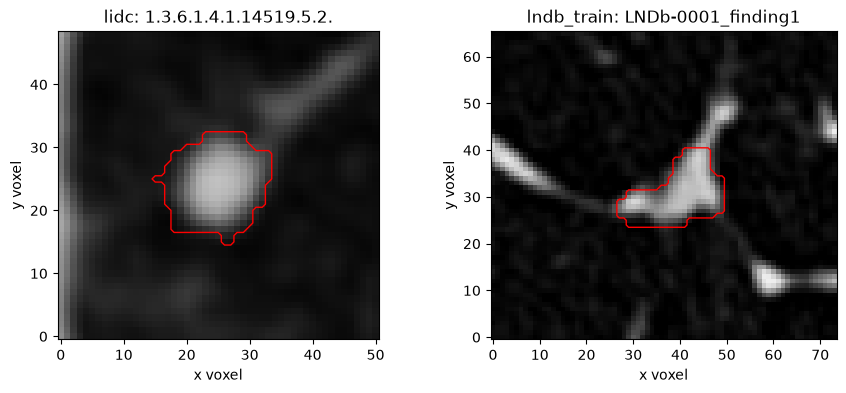

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
for ax, (subset, frame) in zip(axes, manifests.items()):
    sample = frame.loc[frame.status.eq("saved")].iloc[0]
    crop = np.load(PROJECT_ROOT / sample.crop_path, allow_pickle=False)
    center = crop.shape[0] // 2
    ax.imshow(crop[center], cmap="gray", vmin=-1000, vmax=400, origin="lower")
    mask = np.load(PROJECT_ROOT / sample.mask_path, allow_pickle=False)
    ax.contour(mask[center], levels=[0.5], colors=["red"], linewidths=1)
    ax.set(title=f"{subset}: {sample.candidate_id[:22]}", xlabel="x voxel", ylabel="y voxel")
plt.tight_layout()
example_path = OUTPUT_ROOT / "images" / "contour_crop_examples.png"
example_path.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(example_path, dpi=150)
plt.show()


## Próximas Etapas

* **Notebook 03 - Extração de características radiómicas:** Extrai descritores dentro das máscaras da união dos leitores, guardadas com os recortes de treino do LIDC e do LNDb.
* **Notebook 04 - Modelação e validação:** Ajusta e avalia os modelos com separação por paciente, incluindo calibração e validação, e guarda os artefactos de avaliação.
* **Notebook 05 - Recortes esféricos e inferência:** Gera recortes esféricos e as características correspondentes, avalia o desempenho e ajusta os modelos com todos os dados de treino elegíveis para a inferência no conjunto de teste.

## Fontes e Notas Metodológicas

* **Enunciado do projeto:** O guião da unidade curricular (`../../Lab_IA_CD_2026_2027_project1.pdf`) enquadra os requisitos de pré-processamento e avaliação das imagens CT.
* **LNDb:** A documentação fornecida (`../data/lndb/README.pdf`) descreve as coordenadas das anotações, a consolidação dos achados de treino e as condições de utilização dos dados.
* **LIDC-IDRI:** As tabelas de anotações utilizadas neste projeto foram construídas a partir dos dados LIDC e das anotações disponibilizadas pelo `pylidc`, comparadas com os ficheiros XML originais no Notebook 01.
* **IBSI:** A [orientação da IBSI sobre processamento de imagem e interpolação](https://ibsi.readthedocs.io/en/latest/02_Image_processing.html#interpolation) discute os efeitos da interpolação 3D e 2D, incluindo o impacto da escolha na análise de textura. A grelha de 0,4 mm adotada neste projeto resulta da auditoria aos espaçamentos das aquisições.